# DealLens ML Finansal Risk Karşılaştırması
**Mustafa Yüksel · Software Persona Proje 2 · 9 Ekim 2026**

Soru: 64 finansal oranla iflas etiketini ayırt ederken hangi model daha iyi sıralama yapıyor ve daha fazla riskli kayıt yakalamak kaç yanlış alarma yol açıyor?
Python projesine yeni katkı: 64 oranlı lojistik regresyon/MLP karşılaştırması, eğitimde öğrenilen uç değer sınırları, doğrulama recall hedefi, Attr27 duyarlılığı ve grup bootstrap belirsizliği.

Bu veri daha önce incelendi. Sabit ayrımlı eğitim karşılaştırmasıdır; yeni bağımsız dış test değildir. Model skoru kalibre edilmiş güncel iflas yüzdesi veya satın alma kararı değildir.

**Çalıştırma:** Tümünü çalıştır. Veri notebook içinde açık lisanslı sıkıştırılmış kopya olarak bulunur; CSV yüklemen gerekmez. İstersen aynı CSV dosyasını notebook yanına koyabilirsin; dosya özeti doğrulanır. Kod notebook içinde, scripts klasörü gerekmiyor.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('catboost') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','catboost==1.2.10'])
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')

'4'

## 1 Veri kaynağı ve kapsam
[UCI Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data), Tomczak (2016), DOI 10.24432/C5F600, CC BY 4.0. Yalnız `5year.arff`: 5.910 finansal kayıt, 64 oran ve bir yıl sonraki iflas etiketi. 0 iflas yok, 1 iflas var. Bunlar güncel Türkiye şirketleri değildir.
`record_id` kaynak satır numarasıdır; şirket kimliği değildir. `partition`, `partition_order`, `cv_fold` sabit değerlendirme planıdır; hiçbirisi model girdisi değildir. Tam aynı 64 girdili kayıtlar eğitim/doğrulama/test ve CV arasında birlikte tutulur. Şirket kimliği olmadığından şirket düzeyinde ayrışma garanti edilemez.

In [2]:
from pathlib import Path
import json, hashlib, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
import joblib
from catboost import CatBoostClassifier
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix, precision_recall_curve)
FEATURES=[f'Attr{i}' for i in range(1,65)]
TARGET='bankruptcy_label'
SEED=8102026
VERSION='deallens-ml-v1-2026-10-09'

In [3]:
# Açık lisanslı UCI verisinin doğrulanmış kopyası aşağıda sıkıştırılmıştır.
# CSV yüklemek isteğe bağlıdır; eksikse aynı veri notebook içinden açılır.
import base64,zlib
paths=[Path('deallens_financial_risk_64.csv'),Path('data/deallens_financial_risk_64.csv'),Path('/content/deallens_financial_risk_64.csv')]
data_path=next((p for p in paths if p.exists()),None)
if data_path is None:
    data_path=Path('deallens_financial_risk_64.csv')
    data_path.write_bytes(zlib.decompress(base64.b64decode('...')))
assert hashlib.sha256(data_path.read_bytes()).hexdigest()=='2259c9ad2acc4644b1ff9a9775b9981b353d9e57707ed0b4eeedbe2b0a17c900', 'CSV doğrulanmış veriyle eşleşmiyor.'
df=pd.read_csv(data_path)
display(df.head())
print('Boyut:',df.shape,'Hedef:',df[TARGET].value_counts().sort_index().to_dict())
display(df[FEATURES].describe().T.head(10))

,record_id,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,...,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,bankruptcy_label,partition,partition_order,cv_fold
0,1,0.088238,0.55472,0.01134,1.0205,-66.5200,0.342040,0.109490,0.57752,1.0881,...,0.002024,7.2711,4.7343,142.760,2.5568,3.2597,0,test,0,-1
1,2,-0.006202,0.48465,0.23298,1.5998,6.1825,0.000000,-0.006202,1.06340,1.2757,...,0.152220,6.0911,3.2749,111.140,3.2841,3.3700,0,train,1182,2
2,3,0.130240,0.22142,0.57751,3.6082,120.0400,0.187640,0.162120,3.05900,1.1415,...,0.000000,8.7934,2.9870,71.531,5.1027,5.6188,0,validation,0,-1
3,4,-0.089951,0.88700,0.26927,1.5222,-55.9920,-0.073957,-0.089951,0.12740,1.2754,...,2.878700,7.6524,3.3302,147.560,2.4735,5.9299,0,train,2364,1
4,5,0.048179,0.55041,0.10765,1.2437,-22.9590,0.000000,0.059280,0.81682,1.5150,...,0.139380,10.1180,4.0950,106.430,3.4294,3.3622,0,train,0,1


Boyut: (5910, 69) Hedef: {0: 5500, 1: 410}


,count,mean,std,min,25%,50%,75%,max
Attr1,5907.0,-0.022347,6.163655,-4.638900e+02,0.003965,0.04667,0.117050,87.459
Attr2,5907.0,0.465086,5.751283,-4.308700e+02,0.255355,0.45175,0.661635,72.416
Attr3,5907.0,0.189155,1.177729,-7.206700e+01,0.043953,0.21944,0.418430,28.336
Attr4,5889.0,4.892476,91.434574,-4.031100e-01,1.093700,1.65170,2.931000,6845.800
Attr5,5899.0,19.406758,21529.322027,-1.076400e+06,-43.836500,0.49149,48.765000,1250100.000
Attr6,5907.0,0.022584,9.992080,-4.638900e+02,0.000000,0.00000,0.108725,543.250
Attr7,5907.0,-0.111951,9.057135,-5.174800e+02,0.005889,0.05650,0.136905,5.530
Attr8,5892.0,5.737741,102.355101,-3.735100e+00,0.481865,1.14930,2.771275,6868.500
Attr9,5909.0,1.588322,1.548390,-3.496000e+00,1.014800,1.13970,1.825900,65.607
Attr10,5907.0,0.545580,5.763742,-7.144400e+01,0.318940,0.52332,0.720805,339.850


## 2 Veri keşfi
Aşağıdaki üç grafik eğitim bölümünü kullanır. Böylece test dağılımına bakarak ön işleme kararı verilmez. Hiçbir satır silinmez.

In [4]:
class TrainQuantileClipper(TransformerMixin,BaseEstimator):
    """Bounds learned on the current training fold only, no rows discarded."""
    def fit(self,X,y=None):
        self.lower_=np.quantile(X,.01,axis=0)
        self.upper_=np.quantile(X,.99,axis=0)
        return self
    def transform(self,X): return np.clip(np.asarray(X),self.lower_,self.upper_)

In [5]:
def groups_for(df):
    return pd.util.hash_pandas_object(df[FEATURES],index=False).astype(str)

In [6]:
def split_data(df):
    assert df.index.equals(pd.RangeIndex(len(df)))
    assert df.record_id.is_unique and len(df)==5910
    assert set(df[TARGET])=={0,1} and df[TARGET].notna().all()
    assert not np.isinf(df[FEATURES].to_numpy()).any()
    assert not df[FEATURES].isna().all(axis=1).any()
    assert set(df.partition)=={'train','validation','test'}
    groups=groups_for(df)
    split={p:df[df.partition==p].sort_values('partition_order').index.to_numpy()
           for p in ['train','validation','test']}
    for p,idx in split.items():
        assert df.iloc[idx].partition_order.tolist()==list(range(len(idx)))
    for a,b in [('train','validation'),('train','test'),('validation','test')]:
        assert not set(groups.iloc[split[a]]) & set(groups.iloc[split[b]])
    train=split['train']; folds=df.iloc[train].cv_fold.to_numpy()
    assert set(folds)=={0,1,2} and df.loc[df.partition!='train','cv_fold'].eq(-1).all()
    cv=[(np.flatnonzero(folds!=f),np.flatnonzero(folds==f)) for f in [0,1,2]]
    for a,b in cv: assert not set(groups.iloc[train[a]]) & set(groups.iloc[train[b]])
    return split,cv,groups

In [7]:
def configurations():
    cat=lambda:CatBoostClassifier(iterations=300,depth=5,learning_rate=.035,
        l2_leaf_reg=3,random_strength=1,border_count=64,loss_function='Logloss',
        random_seed=SEED,thread_count=4,verbose=False,allow_writing_files=False)
    normalized=lambda model:Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
        ('clip',TrainQuantileClipper()),('scale',StandardScaler()),('model',model)])
    return {
        'Dummy':(FEATURES,Pipeline([('imputer',SimpleImputer(strategy='median')),('model',DummyClassifier(strategy='most_frequent'))])),
        'Logistic 64':(FEATURES,normalized(LogisticRegression(C=1,max_iter=3000,class_weight='balanced',random_state=SEED))),
        'CatBoost 64':(FEATURES,Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('model',cat())])),
        'MLP 64':(FEATURES,normalized(MLPClassifier(hidden_layer_sizes=(32,16),activation='relu',solver='adam',
            alpha=.01,batch_size=128,learning_rate_init=.001,max_iter=600,early_stopping=False,
            tol=1e-4,n_iter_no_change=25,random_state=SEED))),
        'CatBoost without Attr27':([f for f in FEATURES if f!='Attr27'],Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),('model',cat())]))}

In [8]:
def measures(y,s,t):
    pred=(np.asarray(s)>=t).astype(int)
    return {'threshold':float(t),'accuracy':float(accuracy_score(y,pred)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'f1':float(f1_score(y,pred,zero_division=0)),
        'average_precision':float(average_precision_score(y,s)),
        'roc_auc':float(roc_auc_score(y,s)),
        'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}

In [9]:
def f1_threshold(y,s):
    p,r,t=precision_recall_curve(y,s); f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
    return float(t[np.argmax(f)])

In [10]:
def recall_threshold(y,s,target=.8):
    p,r,t=precision_recall_curve(y,s)
    valid=np.flatnonzero(r[:-1]>=target)
    # Highest precision among validation points achieving target recall.
    best=valid[np.argmax(p[:-1][valid])]
    return float(t[best])

In [11]:
def fit_logged(model,X,y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always'); model.fit(X,y)
    return sorted(set(str(w.message) for w in caught))

In [12]:
def group_bootstrap(y,s,t,groups,iterations=600):
    """Uncertainty conditional on this fitted model/test set; groups resampled together."""
    rng=np.random.default_rng(SEED); labels=np.asarray(groups); unique=np.unique(labels)
    rows={g:np.flatnonzero(labels==g) for g in unique};values=[]
    y=np.asarray(y);s=np.asarray(s)
    for _ in range(iterations):
        idx=np.concatenate([rows[g] for g in rng.choice(unique,len(unique),replace=True)])
        if len(np.unique(y[idx]))<2:continue
        m=measures(y[idx],s[idx],t)
        values.append([m[k] for k in ['precision','recall','f1','average_precision']])
    a=np.asarray(values)
    return {k:np.quantile(a[:,j],[.025,.975]).tolist() for j,k in enumerate(['precision','recall','f1','average_precision'])}

In [13]:
def run_study(df,output_dir):
    out=Path(output_dir);out.mkdir(parents=True,exist_ok=True)
    split,cv,groups=split_data(df);train,val,test=[split[p] for p in ['train','validation','test']]
    configs=configurations(); fitted={}; cv_rows=[]; warning_log={}
    protocol={'version':VERSION,'selection':'Highest mean training group CV average precision among Logistic 64, CatBoost 64, MLP 64',
        'eligible':['Logistic 64','CatBoost 64','MLP 64'],'threshold':'Max F1 in validation; second operating point highest precision with validation recall >= 0.80',
        'ablation':'CatBoost without Attr27 is a predeclared diagnostic, not an eligible selection candidate',
        'split':'Frozen partition/order/CV metadata inherited from Python project; no library-dependent resplit',
        'data_previously_explored':True,'independent_external_test':False,
        'seed':SEED,'csv_sha256':hashlib.sha256(df.to_csv(index=False).encode()).hexdigest(),
        'parameters':{n:m.named_steps['model'].get_params() for n,(_,m) in configs.items()}}
    (out/'protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf-8')
    for name,(features,model) in configs.items():
        aps=[];ws=[]
        for a,b in cv:
            fold=clone(model);ws+=fit_logged(fold,df.iloc[train[a]][features],df.iloc[train[a]][TARGET])
            aps.append(float(average_precision_score(df.iloc[train[b]][TARGET],fold.predict_proba(df.iloc[train[b]][features])[:,1])))
        ws+=fit_logged(model,df.iloc[train][features],df.iloc[train][TARGET])
        s=model.predict_proba(df.iloc[val][features])[:,1]
        t=.5 if name=='Dummy' else f1_threshold(df.iloc[val][TARGET],s)
        fitted[name]={'model':model,'features':features,'threshold':t,'training_record_ids':df.iloc[train].record_id.tolist(),'version':VERSION}
        cv_rows.append({'model':name,'fold_ap':aps,'mean_ap':float(np.mean(aps)),'std_ap':float(np.std(aps))})
        warning_log[name]=sorted(set(ws));print(f'{name}: CV AP={np.mean(aps):.4f}',flush=True)
    selected=max([r for r in cv_rows if r['model'] in protocol['eligible']],key=lambda r:r['mean_ap'])['model']
    bundle=fitted[selected];vscore=bundle['model'].predict_proba(df.iloc[val][bundle['features']])[:,1]
    recall_t=recall_threshold(df.iloc[val][TARGET],vscore)
    selection={'selected_model':selected,'cv':cv_rows,'f1_threshold':bundle['threshold'],'recall80_threshold':recall_t,'test_used_for_selection':False}
    (out/'selection_before_test.json').write_text(json.dumps(selection,ensure_ascii=False,indent=2),encoding='utf-8')
    models={};predictions=[];operating={}
    for name,b in fitted.items():
        models[name]={}
        for part,idx in split.items():
            s=b['model'].predict_proba(df.iloc[idx][b['features']])[:,1]
            models[name][part]=measures(df.iloc[idx][TARGET],s,b['threshold'])
            if part=='test':predictions.append(pd.DataFrame({'record_id':df.iloc[idx].record_id.to_numpy(),'actual_label':df.iloc[idx][TARGET].to_numpy(),'score':s,'prediction':(s>=b['threshold']).astype(int),'model':name}))
    for part,idx in split.items():
        s=bundle['model'].predict_proba(df.iloc[idx][bundle['features']])[:,1]
        operating[part]=measures(df.iloc[idx][TARGET],s,recall_t)
    ts=bundle['model'].predict_proba(df.iloc[test][bundle['features']])[:,1]
    intervals=group_bootstrap(df.iloc[test][TARGET],ts,bundle['threshold'],groups.iloc[test])
    pd.concat(predictions).to_csv(out/'test_predictions.csv',index=False)
    manifest=df[['record_id',TARGET,'partition','partition_order','cv_fold']].copy();manifest['group_id']=groups;manifest.to_csv(out/'split_manifest.csv',index=False)
    joblib.dump(bundle,out/'selected_model.joblib')
    result={'version':VERSION,'selected_model':selected,'cv':cv_rows,'models':models,
        'recall80_operating_point':operating,'bootstrap_95_intervals':intervals,'bootstrap_iterations':600,
        'warnings':warning_log,'data':{'rows':len(df),'class_counts':df[TARGET].value_counts().sort_index().to_dict(),
        'partitions':{p:{'rows':len(idx),'positive':int(df.iloc[idx][TARGET].sum())} for p,idx in split.items()},
        'missing_cells':int(df[FEATURES].isna().sum().sum()),'duplicate_extra_rows':int(df[FEATURES].duplicated().sum())},
        'mlp_iterations':int(fitted['MLP 64']['model'].named_steps['model'].n_iter_),
        'environment':{'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','catboost','joblib']}},
        'limitations':['Data previously explored; model family choice informed by Python study','No company identifier or calendar split','No externally validated Turkish company performance','Scores uncalibrated; not a current bankruptcy probability','Bootstrap conditional on fitted model and this historical test set']}
    (out/'results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
    return result,fitted,split

In [14]:
def predict_checked(bundle,frame):
    if not isinstance(frame,pd.DataFrame) or frame.empty or frame.columns.duplicated().any():raise ValueError('Geçerli ve boş olmayan tablo gerekli.')
    if set(bundle['features'])-set(frame.columns):raise ValueError('Gerekli oran sütunları eksik.')
    X=frame[bundle['features']].apply(pd.to_numeric,errors='raise')
    if np.isinf(X.to_numpy()).any() or X.isna().all(axis=1).any():raise ValueError('Sonsuz veya tamamen eksik kayıt kabul edilmez.')
    s=bundle['model'].predict_proba(X)[:,1]
    return pd.DataFrame({'model_score':s,'predicted_label':(s>=bundle['threshold']).astype(int)})

,kayıt,pozitif
train,3546,246
validation,1182,82
test,1182,82


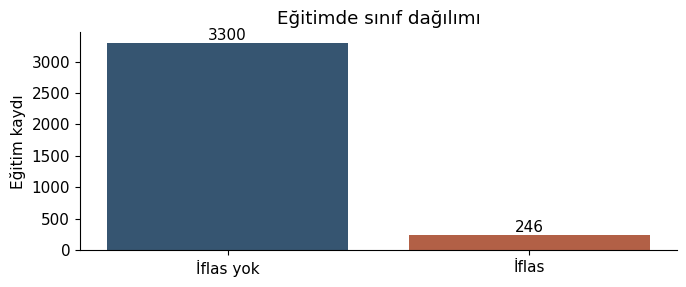

Pozitif oranı %6.94; tümüne negatif demek yüksek accuracy verebilir fakat hiçbir iflas yakalamaz.


In [15]:
split,cv,groups=split_data(df)
train_df=df.iloc[split['train']]
display(pd.DataFrame({p:{'kayıt':len(i),'pozitif':int(df.iloc[i][TARGET].sum())} for p,i in split.items()}).T)
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
chart_dir=Path('outputs/charts');chart_dir.mkdir(parents=True,exist_ok=True)
def finish_plot(name):
    plt.tight_layout();plt.savefig(chart_dir/name,dpi=160,bbox_inches='tight');plt.show();plt.close()
counts=train_df[TARGET].value_counts().sort_index()
plt.figure(figsize=(7,3));bars=plt.bar(['İflas yok','İflas'],counts,color=['#365571','#B26046'])
plt.bar_label(bars);plt.ylabel('Eğitim kaydı');plt.title('Eğitimde sınıf dağılımı');finish_plot('class_counts.png')
print(f'Pozitif oranı %{100*train_df[TARGET].mean():.2f}; tümüne negatif demek yüksek accuracy verebilir fakat hiçbir iflas yakalamaz.')

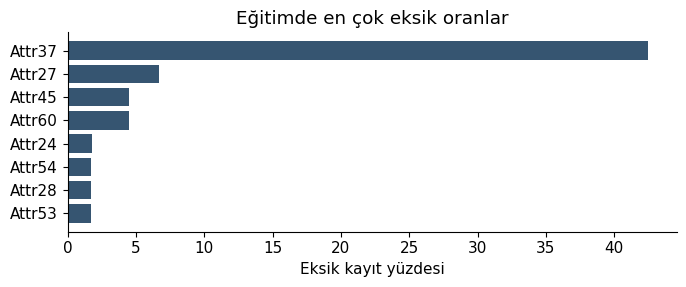

En çok eksik sütun Attr37: %42.47. Medyan ve eksik göstergeleri yalnız eğitimde öğrenilir. Eksiklik hedef sızıntısı kanıtı değildir; başka veriye taşınırken risk olabilir.


In [16]:
missing=100*train_df[FEATURES].isna().mean().sort_values(ascending=False).head(8)
plt.figure(figsize=(7,3));plt.barh(missing.index[::-1],missing.values[::-1],color='#365571')
plt.xlabel('Eksik kayıt yüzdesi');plt.title('Eğitimde en çok eksik oranlar');finish_plot('missing.png')
print(f'En çok eksik sütun {missing.index[0]}: %{missing.iloc[0]:.2f}. Medyan ve eksik göstergeleri yalnız eğitimde öğrenilir. Eksiklik hedef sızıntısı kanıtı değildir; başka veriye taşınırken risk olabilir.')

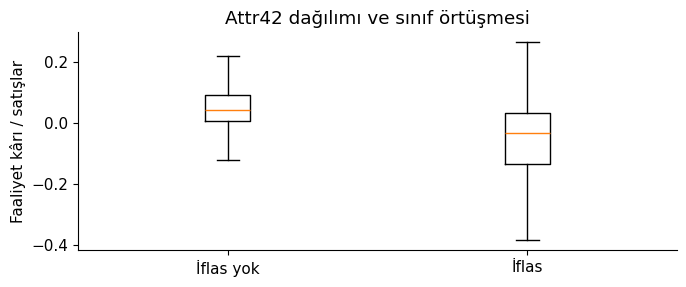

,count,median
bankruptcy_label,,
0,3300,0.043319
1,246,-0.031682


Grafikte 1/99 yüzdelik sınırı yalnız görünümü okunur kılar. Sınıflar örtüşür; tek oran kesin karar kuralı değildir. Model için uç değer sınırlaması farklıdır ve her eğitim katında yeniden öğrenilir.


In [17]:
column='Attr42';lo,hi=train_df[column].quantile([.01,.99])
shown=[train_df.loc[train_df[TARGET]==k,column].dropna().clip(lo,hi).to_numpy() for k in [0,1]]
plt.figure(figsize=(7,3));plt.boxplot(shown,tick_labels=['İflas yok','İflas'],showfliers=False)
plt.ylabel('Faaliyet kârı / satışlar');plt.title('Attr42 dağılımı ve sınıf örtüşmesi');finish_plot('margin.png')
display(train_df.groupby(TARGET)[column].agg(['count','median']))
print('Grafikte 1/99 yüzdelik sınırı yalnız görünümü okunur kılar. Sınıflar örtüşür; tek oran kesin karar kuralı değildir. Model için uç değer sınırlaması farklıdır ve her eğitim katında yeniden öğrenilir.')

## 3 Ön işleme ve modeller
Medyan doldurma tüm modellerde; eksik göstergeleri ana üç modelde. Lojistik ve MLP için her eğitim katında öğrenilen 1/99 yüzdelik sınırlama ve StandardScaler vardır. CatBoost için oranları standartlaştırmak gerekmediğinden eklenmedi. Hedef/kimlik/ayrım sütunları girdi dışında.

| Model | Gerekçe ve ayar |
|---|---|
| Dummy | Tümünü negatif söyleyen referans |
| Lojistik | Doğrusal temel; C=1, balanced, max_iter=3000 |
| CatBoost | Oran etkileşimleri; 300 ağaç, depth=5, lr=.035, L2=3 |
| Küçük MLP | İki gizli katman 32 ve 16 ReLU; tek sigmoid çıktı; log-loss, Adam, lr=.001, L2=.01, batch=128, en fazla 600 epoch |
| Attr27 çıkarılmış CatBoost | Aynı ayarlar; eksiklik/özellik bağımlılığı için önceden belirlenmiş duyarlılık incelemesi |

MLP sınıf ağırlığı kullanmaz; dengesiz veride bunun etkisi sınırlılık olarak yorumlanır. Ayrı grup ihlaline yol açabilecek otomatik iç doğrulama kapalıdır. Durdurma eğitim loss değişimine dayanır. Gerçek epoch ve uyarılar aşağıda kaydedilir.

**Ölçüm planı:** eğitim içinde üç sabit grup CV katı; ana üç model arasında en yüksek ortalama average precision seçimi. Eşik ayrı doğrulamada maksimum F1. İkinci eşik doğrulamada recall ≥.80 sağlayan noktalar arasında en yüksek precision. Test yalnız bu kararlar kaydedildikten sonra ölçülür. Attr27 incelemesi seçime katılmaz. Model bütün veride yeniden eğitilmez.

In [18]:
result,fitted,split=run_study(df,'outputs')
display(pd.DataFrame(result['cv']))
print('Seçilen:',result['selected_model'],'MLP epoch:',result['mlp_iterations'])
print('Eğitim uyarıları:',result['warnings'])

Dummy: CV AP=0.0694
Logistic 64: CV AP=0.6164
CatBoost 64: CV AP=0.7702
MLP 64: CV AP=0.6551
CatBoost without Attr27: CV AP=0.6043


,model,fold_ap,mean_ap,std_ap
0,Dummy,"[0.06937394247038917, 0.06937394247038917, 0.0...",0.069374,0.000000
1,Logistic 64,"[0.5536062687712522, 0.6405054802619254, 0.654...",0.616356,0.044761
2,CatBoost 64,"[0.7272996832169335, 0.7843686191949414, 0.798...",0.770216,0.030927
3,MLP 64,"[0.6691435135684823, 0.6273325902144021, 0.668...",0.655114,0.019645
4,CatBoost without Attr27,"[0.5686803654508383, 0.6213563340297168, 0.622...",0.604345,0.025228


Seçilen: CatBoost 64 MLP epoch: 243
Eğitim uyarıları: {'Dummy': [], 'Logistic 64': ['scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.'], 'CatBoost 64': [], 'MLP 64': [], 'CatBoost without Attr27': []}


## 4 Değerlendirme
Accuracy bütün doğru etiketlerin oranıdır. Precision alarm verilenlerin ne kadarının pozitif olduğu, recall gerçek pozitiflerin ne kadarının yakalandığıdır. F1 ikisini birleştirir. Average precision, precision–recall eğrisinin basamak ağırlıklı özetidir; trapez PR alanıyla aynı ad altında kullanılmaz. ROC AUC ayrıca gösterilir. Seçim CV ölçümü ve test başarısı farklıdır.

,accuracy,precision,recall,f1,average_precision,roc_auc,threshold
Dummy,0.930626,0.0,0.0,0.0,0.069374,0.5,0.5
Logistic 64,0.950931,0.706897,0.5,0.585714,0.657201,0.917616,0.955746
CatBoost 64,0.962775,0.756757,0.682927,0.717949,0.79997,0.95643,0.334473
MLP 64,0.950931,0.666667,0.585366,0.623377,0.64967,0.8849,0.586539
CatBoost without Attr27,0.950085,0.661972,0.573171,0.614379,0.681643,0.920277,0.30839


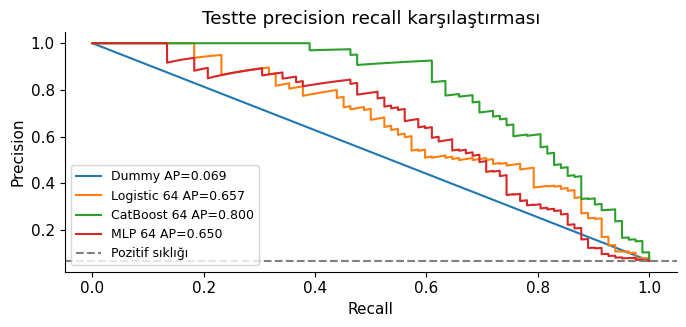

Grafik sıralama gücünü gösterir. Tek bir iş eşiği seçmez. CV sonucuna göre seçilmiş model testte daha iyi/az iyi görünse de seçimi değiştirmiyoruz.


In [19]:
table=pd.DataFrame({n:m['test'] for n,m in result['models'].items()}).T
display(table[['accuracy','precision','recall','f1','average_precision','roc_auc','threshold']])
chosen=result['selected_model'];bundle=fitted[chosen];test_idx=split['test'];y=df.iloc[test_idx][TARGET]
plt.figure(figsize=(7,3.4))
for n,b in fitted.items():
    if n=='CatBoost without Attr27':continue
    s=b['model'].predict_proba(df.iloc[test_idx][b['features']])[:,1]
    p,r,_=precision_recall_curve(y,s);plt.plot(r,p,label=f"{n} AP={result['models'][n]['test']['average_precision']:.3f}")
plt.axhline(y.mean(),ls='--',color='gray',label='Pozitif sıklığı');plt.xlabel('Recall');plt.ylabel('Precision');plt.legend(fontsize=9)
plt.title('Testte precision recall karşılaştırması');finish_plot('precision_recall.png')
print('Grafik sıralama gücünü gösterir. Tek bir iş eşiği seçmez. CV sonucuna göre seçilmiş model testte daha iyi/az iyi görünse de seçimi değiştirmiyoruz.')

,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,confusion_matrix
F1 eşiği,0.334473,0.962775,0.756757,0.682927,0.717949,0.79997,0.95643,"[[1082, 18], [26, 56]]"
Doğrulamada recall80 eşiği,0.24898,0.959391,0.7125,0.695122,0.703704,0.79997,0.95643,"[[1077, 23], [25, 57]]"


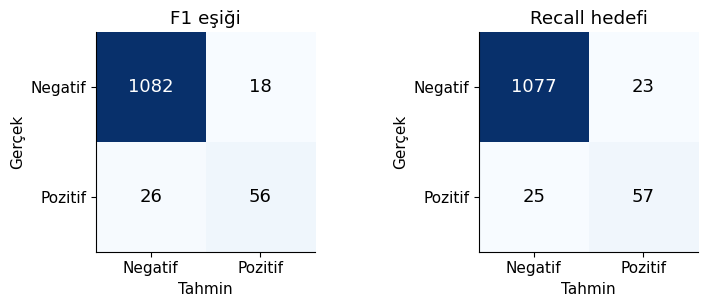

F1 eşiğinde 56 yakalanan, 26 kaçan pozitif, 18 yanlış alarm. Doğrulamada .80 recall testte .80 garantisi değildir.
Koşullu grup bootstrap %95 aralıkları: {'precision': [0.65, 0.8551242236024844], 'recall': [0.5713403880070547, 0.7848327305605786], 'f1': [0.632249245852187, 0.7941228619107217], 'average_precision': [0.7177776004003471, 0.8713732080176151]}


In [20]:
base=result['models'][chosen]['test'];high=result['recall80_operating_point']['test']
display(pd.DataFrame({'F1 eşiği':base,'Doğrulamada recall80 eşiği':high}).T)
fig,axes=plt.subplots(1,2,figsize=(8,3.2))
for ax,(label,m) in zip(axes,[('F1 eşiği',base),('Recall hedefi',high)]):
    matrix=np.array(m['confusion_matrix']);ax.imshow(matrix,cmap='Blues')
    for i in range(2):
        for j in range(2):ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='white' if matrix[i,j]>matrix.max()/2 else 'black',fontsize=13)
    ax.set_xticks([0,1],['Negatif','Pozitif']);ax.set_yticks([0,1],['Negatif','Pozitif']);ax.set_xlabel('Tahmin');ax.set_ylabel('Gerçek');ax.set_title(label)
finish_plot('confusion.png')
tn,fp=base['confusion_matrix'][0];fn,tp=base['confusion_matrix'][1]
print(f'F1 eşiğinde {tp} yakalanan, {fn} kaçan pozitif, {fp} yanlış alarm. Doğrulamada .80 recall testte .80 garantisi değildir.')
print('Koşullu grup bootstrap %95 aralıkları:',result['bootstrap_95_intervals'])

## 5 Hata ve genelleme
Eğitim başarısı yüksekken doğrulama/test düşmesi aşırı öğrenmeye işaret edebilir. Aynı veri geçmişte incelendiğinden bu analiz yeni bağımsız dış doğrulama yerine geçmez.

In [21]:
display(pd.DataFrame({p:result['models'][chosen][p] for p in ['train','validation','test']}).T[['precision','recall','f1','average_precision']])
s=bundle['model'].predict_proba(df.iloc[test_idx][bundle['features']])[:,1];pred=(s>=bundle['threshold']).astype(int)
errors=df.iloc[test_idx][['record_id',TARGET,'Attr2','Attr4','Attr42']].copy()
errors['score']=s;errors['prediction']=pred;errors['missing_count']=df.iloc[test_idx][FEATURES].isna().sum(axis=1).to_numpy()
errors['error_type']=np.where((y.to_numpy()==1)&(pred==0),'FN',np.where((y.to_numpy()==0)&(pred==1),'FP','correct'))
display(errors[errors.error_type!='correct'].sort_values('score',ascending=False).head(12))
display(errors.groupby('error_type').agg(records=('record_id','size'),median_missing=('missing_count','median'),median_score=('score','median')))
errors.to_csv('outputs/error_analysis.csv',index=False)
full=result['models']['CatBoost 64']['test']['average_precision'];abl=result['models']['CatBoost without Attr27']['test']['average_precision']
print(f'Attr27 dahil AP={full:.3f}, çıkarılmış AP={abl:.3f}. Bu değişim özelliğe/eksiklik bilgisinin birlikte çıkarılmasına duyarlılıktır; doğrudan sızıntı veya nedensellik kanıtı değildir.')

,precision,recall,f1,average_precision
train,0.986047,0.861789,0.91974,0.965436
validation,0.885714,0.756098,0.815789,0.871334
test,0.756757,0.682927,0.717949,0.79997


,record_id,bankruptcy_label,Attr2,Attr4,Attr42,score,prediction,missing_count,error_type
1027,1028,0,0.05059,4.33450,-0.095743,0.879981,1,2,FP
1294,1295,0,1.24710,0.55583,0.053333,0.849705,1,2,FP
1147,1148,0,0.65867,0.94959,0.026209,0.822713,1,1,FP
626,627,0,0.78191,0.71749,-0.036963,0.810435,1,1,FP
2658,2659,0,0.42229,0.78469,-0.194310,0.427093,1,1,FP
3990,3991,0,0.77503,1.28510,0.126330,0.420194,1,3,FP
677,678,0,2.99790,0.21344,-0.098728,0.411402,1,0,FP
2008,2009,0,0.72654,1.27670,-0.064961,0.403638,1,1,FP
4914,4915,0,1.92290,4.13610,0.053031,0.392505,1,5,FP
298,299,0,1.22630,0.99908,0.009159,0.387938,1,0,FP


,records,median_missing,median_score
error_type,,,
FN,26,1.0,0.080494
FP,18,1.0,0.390221
correct,1138,0.0,0.009098


Attr27 dahil AP=0.800, çıkarılmış AP=0.682. Bu değişim özelliğe/eksiklik bilgisinin birlikte çıkarılmasına duyarlılıktır; doğrudan sızıntı veya nedensellik kanıtı değildir.


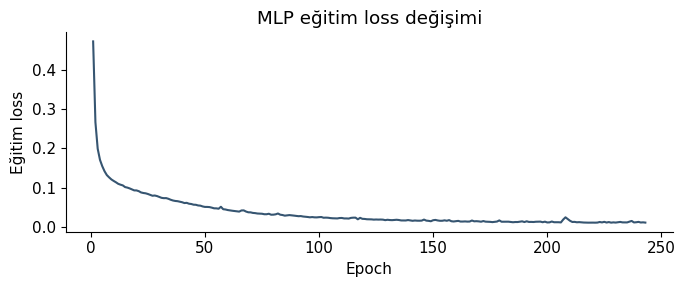

Bu eğri eğitim lossudur; tek başına genelleme başarısı göstermez.


,model_score,predicted_label
0,0.001726,0
1,0.002079,0
2,0.030756,0


Örnek skorlar kalibre edilmiş güncel iflas yüzdesi değildir.


In [22]:
loss=fitted['MLP 64']['model'].named_steps['model'].loss_curve_
plt.figure(figsize=(7,3));plt.plot(np.arange(1,len(loss)+1),loss,color='#365571')
plt.xlabel('Epoch');plt.ylabel('Eğitim loss');plt.title('MLP eğitim loss değişimi');finish_plot('mlp_loss.png')
print('Bu eğri eğitim lossudur; tek başına genelleme başarısı göstermez.')
example=predict_checked(bundle,df.iloc[test_idx[:3]])
display(example)
print('Örnek skorlar kalibre edilmiş güncel iflas yüzdesi değildir.')

## 6 Sonuç ve geliştirme
Sonuçları `outputs/results.json` ve kayıtlı tahminler taşır. Tabular boosting, doğrusal model ve MLP aynı kayıtlarla karşılaştırılır; sinir ağı kullanmak tek başına daha yüksek başarı sağlamaz. Seçim test yerine eğitim CV ile yapılır.

İyileştirme: farklı tarih ve şirket kimliğiyle dış veri; şirket ve zaman düzeyinde ayrım; tahmin anında oranların bulunabilirliği; gerçek yanlış alarm/kaçırma maliyetleri; ayrı veride kalibrasyon; MLP ağırlıklı loss/hyperparameter çalışması yalnız eğitim içinde. Bootstrap aralıkları bu model ve test kayıtlarına koşulludur, ülke/zaman değişimini kapsamaz.

Kaynaklar: [UCI veri](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data), [sklearn MLP](https://scikit-learn.org/stable/modules/neural_networks_supervised.html), [sklearn metrikler](https://scikit-learn.org/stable/modules/model_evaluation.html). Erişim 09.10.2026. AI destekli geliştirme kullanıldı; Mustafa'nın kavrayışı ayrıca çalışılmalıdır.

**Kendi cümlelerinle açıkla:** Neden accuracy yeterli değil? Medyan/scaler neden train içinde öğreniliyor? CV/validation/test ayrı ne yapıyor? Recall hedefi yanlış alarmı nasıl değiştiriyor? Attr27 sonucu neden sızıntı kanıtı değil? Bu veriyi güncel bir şirkete neden doğrudan uygulamıyoruz?